# Etapa 2 — Preparação dos Dados e Modelagem

Cada pessoa trabalha na sua seção abaixo. A Pessoa 4 integra tudo no final.

## Pessoa 1 — Limpeza e base comum

**Entrega:** função `limpar(df)`, função `avaliar(pipeline)` e a primeira linha da tabela comparativa.

- Tratar redundantes e inconsistentes: padronizar texto, valores impossíveis → ausentes, remover duplicatas e linhas contraditórias
- Remover colunas copiadas, a constante e as de vazamento
- Montar a função de avaliação usada por todos
- Rodar o modelo base com e sem `score_ids_legado`

### Limpeza dos dados

Nesta parte da Etapa 2 eu deixo a base limpa para o resto do grupo usar. Parti dos problemas que a análise exploratória da Etapa 1 encontrou (texto com grafias diferentes, valores impossíveis, colunas repetidas ou com vazamento, linhas duplicadas e contraditórias) e apliquei só regras fixas, que não aprendem nada dos dados.

Ficou de fora de propósito: imputar os ausentes, codificar os textos e normalizar os números. Isso é com as outras pessoas, dentro do pipeline de cada uma, para o ajuste ser feito só com o treino de cada fold.

As regras ficam no arquivo `limpeza.py`, na função `limpar(df, eh_treino)`. Aqui eu uso os passos dela um por um para mostrar o efeito de cada um, e no final confiro que a função inteira dá o mesmo resultado.

### 0. Leitura dos dados

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import limpeza as L   # as regras de limpeza ficam em limpeza.py

pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
treino = pd.read_csv(PASTA / "treino.csv")
teste = pd.read_csv(PASTA / "teste_sem_rotulo.csv")
ALVO = "class"

print("treino:", treino.shape, "| teste:", teste.shape)

treino: (69833, 50) | teste: (24333, 50)


### 1. Padronizar o texto

`protocol_type` e `service` ficam sem espaços nas pontas e em minúsculas; `flag` fica sem espaços e em maiúsculas (é assim que ela aparece na maioria das linhas). Sem isso, `tcp` e `TCP` virariam categorias diferentes na hora de codificar. Conto quantas linhas mudaram.

In [2]:
# passo 1 da limpeza, nos dois arquivos
tr1 = L.padronizar_texto(treino)
te1 = L.padronizar_texto(teste)

# uma linha "mudou" se o valor ficou diferente do original (ausente continua ausente)
def mudou(antes, depois, cols):
    return antes[cols].ne(depois[cols]) & antes[cols].notna()

cols_texto = L.TEXTO_MINUSCULA + L.TEXTO_MAIUSCULA
m_tr, m_te = mudou(treino, tr1, cols_texto), mudou(teste, te1, cols_texto)

passo1 = pd.DataFrame({"treino": m_tr.sum(), "teste": m_te.sum()})
passo1.loc["linhas com alguma mudança"] = [m_tr.any(axis=1).sum(), m_te.any(axis=1).sum()]
display(passo1)

# conferindo: sobra uma grafia só por valor
print({c: tr1[c].nunique() for c in cols_texto})

,treino,teste
protocol_type,1455,0
service,1531,100
flag,1340,0
linhas com alguma mudança,4235,100


{'protocol_type': 3, 'service': 67, 'flag': 11}


**Conclusão do passo 1**

- No treino mudaram 4.235 linhas (`protocol_type` 1.455, `flag` 1.340 e `service` 1.531). Depois disso sobram só 3 protocolos, 11 flags e 67 serviços, sem grafias repetidas.
- No teste mudaram 100 linhas, todas em `service`. Não são erros de digitação: são serviços que já vêm em maiúsculas (`IRC`, `X11` e `Z39_50`), e a regra os deixa iguais aos do treino. Sem isso eles não casariam com as categorias do treino.

### 2. Valores impossíveis viram ausentes

Pela definição dos atributos, não faz sentido ter `duration`, `src_bytes` ou `dst_bytes` negativos, taxas (`*_rate`) acima de 1, `count` e `srv_count` acima de 511, ou `dst_host_count` e `dst_host_srv_count` acima de 255. Como os valores errados não seguem um fator de escala único (a Etapa 1 viu 1,5, 2, 5, 10 e até 512.000), não dá para "consertar": transformo em `NaN` e deixo a imputação para o pipeline.

In [3]:
tr2 = L.impossiveis_para_nan(tr1)
te2 = L.impossiveis_para_nan(te1)

# valores que viraram NaN = ausentes depois - ausentes antes, coluna por coluna
novos_tr = tr2.isna().sum() - tr1.isna().sum()
novos_te = te2.isna().sum() - te1.isna().sum()
passo2 = pd.DataFrame({"treino": novos_tr, "teste": novos_te}).fillna(0).astype(int)
passo2 = passo2[(passo2 > 0).any(axis=1)].sort_values("treino", ascending=False)
display(passo2)

# linhas afetadas = linhas que ganharam pelo menos um NaN novo
lin_tr = (tr2.isna() & tr1.notna()).any(axis=1).sum()
lin_te = (te2.isna() & te1.notna()).any(axis=1).sum()
print(f"Valores trocados por NaN: treino {passo2['treino'].sum()} | teste {passo2['teste'].sum()}")
print(f"Linhas afetadas: treino {lin_tr} | teste {lin_te}")

,treino,teste
dst_host_count,912,0
dst_host_srv_diff_host_rate,739,0
dst_host_srv_rerror_rate,714,0
rerror_rate,683,0
dst_host_same_srv_rate,670,0
dst_host_diff_srv_rate,623,0
srv_count,507,0
count,464,0
duration,358,0
src_bytes,189,0


Valores trocados por NaN: treino 5859 | teste 0
Linhas afetadas: treino 5650 | teste 0


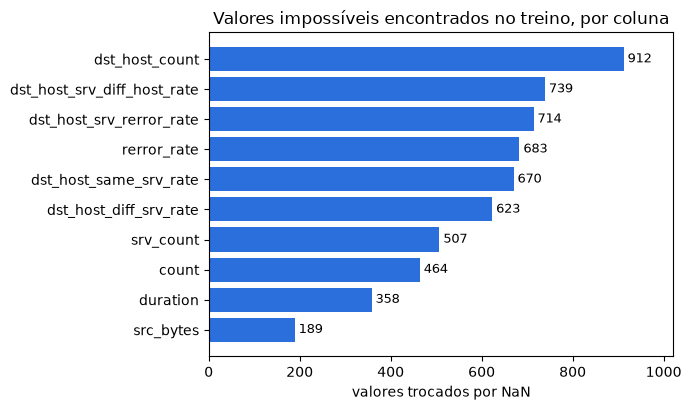

In [4]:
# gráfico 1: onde estavam os valores impossíveis (só o treino tem)
dados = passo2["treino"].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(dados.index, dados.values, color=AZUL)
for i, v in enumerate(dados.values):   # escreve o número no fim de cada barra
    ax.text(v, i, f" {v}", va="center", fontsize=9)
ax.set_xlim(0, dados.max() * 1.12)
ax.set_xlabel("valores trocados por NaN")
ax.set_title("Valores impossíveis encontrados no treino, por coluna")
plt.tight_layout(); plt.show()

**Conclusão do passo 2**

- 5.859 valores do treino viraram `NaN`, em 5.650 linhas. O teste não tem nenhum valor impossível (os 18 que a Etapa 1 achou no teste eram todos do `su_attempted`, tratado no passo 3).
- Os maiores grupos são `dst_host_count` (912) e as taxas acima de 1, entre 623 e 739 em cada uma das cinco.
- Esses `NaN` se somam aos que já existiam, então o pipeline vai ter mais ausentes para imputar do que a Etapa 1 mostrou.

### 3. `su_attempted = 2` vira 1

Essa coluna deveria ser só 0 ou 1. O valor 2 aparece no treino e no teste, na mesma proporção (a Etapa 1 viu cerca de 0,07% nos dois), então não parece erro colocado só no treino. Tratei como "houve tentativa" e juntei com o 1.

In [5]:
tr3 = L.corrigir_su_attempted(tr2)
te3 = L.corrigir_su_attempted(te2)

print("treino antes:", treino["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("treino depois:", tr3["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("teste antes:", teste["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("teste depois:", te3["su_attempted"].value_counts(dropna=False).sort_index().to_dict())

treino antes: {0.0: 66462, 1.0: 16, 2.0: 49, nan: 3306}
treino depois: {0.0: 66462, 1.0: 65, nan: 3306}
teste antes: {0.0: 23123, 1.0: 9, 2.0: 18, nan: 1183}
teste depois: {0.0: 23123, 1.0: 27, nan: 1183}


**Conclusão do passo 3**

- 49 linhas do treino e 18 do teste tinham `su_attempted = 2`. Agora a coluna só tem 0, 1 ou ausente nas duas bases (os ausentes não foram mexidos).

### 4. Remover colunas

Saem 8 colunas, todas por motivos que a Etapa 1 mostrou:

- **cópias** de colunas que já existem: `src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct` e `protocolo_cod`;
- **constante**: `num_outbound_cmds` (um valor só, não ajuda em nada);
- **vazamento**: `tempo_resposta_analista_min` e `tipo_alerta_soc`, que só existem depois que um analista olha a conexão e entregam a classe.

> **Aviso para o grupo:** `score_ids_legado` foi **mantida**. Não sabemos de onde vem essa nota (se vem de um sistema em tempo real ou se foi gerada depois), então o grupo ainda vai decidir se usa. Quem for modelar deve testar com e sem ela.

In [6]:
tr4 = L.remover_colunas(tr3)
te4 = L.remover_colunas(te3)

print("colunas removidas:", L.REMOVER)
print(f"treino: {tr3.shape[1]} -> {tr4.shape[1]} colunas | teste: {te3.shape[1]} -> {te4.shape[1]} colunas")
print("score_ids_legado continua na base:", "score_ids_legado" in tr4.columns and "score_ids_legado" in te4.columns)

colunas removidas: ['src_bytes_kb', 'dst_bytes_kb', 'total_bytes', 'same_srv_pct', 'protocolo_cod', 'num_outbound_cmds', 'tempo_resposta_analista_min', 'tipo_alerta_soc']
treino: 50 -> 42 colunas | teste: 50 -> 42 colunas
score_ids_legado continua na base: True


**Conclusão do passo 4**

- Cada base ficou com 42 colunas: o treino com `class` e o teste com `id`, e as outras 41 iguais nos dois.

### 5. Duplicatas e linhas contraditórias (só no treino)

Esse passo só vale para o treino, depois dos passos anteriores e **nesta ordem**:

1. tiro as linhas exatamente iguais (mesmos atributos e mesma classe), ficando com uma cópia de cada;
2. depois, o que sobrar de linhas com atributos idênticos e classes diferentes eu tiro **inteiro**: não dá para saber qual rótulo está certo, então nenhuma das linhas do grupo fica.

Se a ordem fosse a contrária, as cópias de uma mesma linha contariam como "classes iguais" e o grupo poderia passar despercebido ou ser contado errado. Também não faço isso no teste, porque lá não se pode perder linha.

In [7]:
n0 = len(tr4)
anom0 = (tr4[ALVO] == "anomaly").mean() * 100

tr5a = L.remover_duplicatas(tr4)
n1 = len(tr5a)
anom1 = (tr5a[ALVO] == "anomaly").mean() * 100

tr5 = L.remover_contraditorias(tr5a)
n2 = len(tr5)
anom2 = (tr5[ALVO] == "anomaly").mean() * 100

# quantos grupos contraditórios foram tirados (só pra mostrar; a função já fez o trabalho)
atrib = [c for c in tr5a.columns if c != ALVO]
tam_grupo = tr5a.groupby(atrib, dropna=False)[ALVO].transform("size")
n_grupos = tr5a[tam_grupo > 1].groupby(atrib, dropna=False).ngroups

etapas = pd.DataFrame({
    "linhas": [n0, n1, n2],
    "anomalias": [(tr4[ALVO] == "anomaly").sum(), (tr5a[ALVO] == "anomaly").sum(), (tr5[ALVO] == "anomaly").sum()],
    "% anomalias": [anom0, anom1, anom2],
}, index=["antes", "sem duplicatas exatas", "sem grupos contraditórios"])
etapas["normais"] = etapas["linhas"] - etapas["anomalias"]
display(etapas[["linhas", "normais", "anomalias", "% anomalias"]].round(2))

print(f"Duplicatas removidas: {n0 - n1}")
print(f"Linhas contraditórias removidas: {n1 - n2} (em {n_grupos} grupos)")
print(f"Proporção de anomalias: {anom0:.2f}% -> {anom2:.2f}%")

,linhas,normais,anomalias,% anomalias
antes,69833,65754,4079,5.84
sem duplicatas exatas,58478,54959,3519,6.02
sem grupos contraditórios,55074,53257,1817,3.30


Duplicatas removidas: 11355
Linhas contraditórias removidas: 3404 (em 1702 grupos)
Proporção de anomalias: 5.84% -> 3.30%


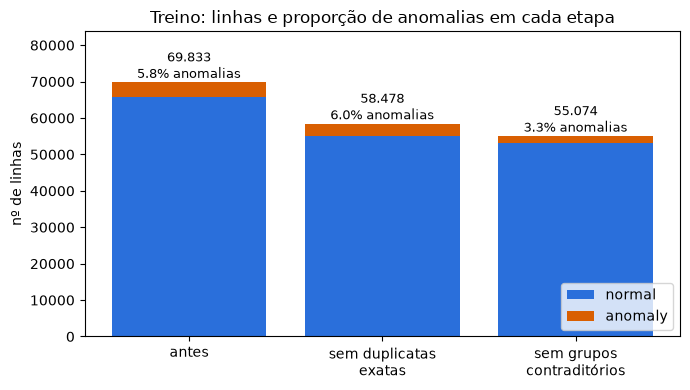

In [8]:
# gráfico 2: linhas do treino em cada etapa, com a % de anomalias
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
ax.bar(x, etapas["normais"], color=AZUL, label="normal")
ax.bar(x, etapas["anomalias"], bottom=etapas["normais"], color=LARANJA, label="anomaly")
for i, (n, p) in enumerate(zip(etapas["linhas"], etapas["% anomalias"])):
    ax.text(i, n, f"{n:,}\n{p:.1f}% anomalias".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["antes", "sem duplicatas\nexatas", "sem grupos\ncontraditórios"])
ax.set_ylim(0, etapas["linhas"].max() * 1.2)
ax.set_ylabel("nº de linhas")
ax.set_title("Treino: linhas e proporção de anomalias em cada etapa")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusão do passo 5**

- Saíram 11.355 duplicatas exatas (o treino foi de 69.833 para 58.478 linhas). A proporção de anomalias subiu de 5,84% para 6,02%.
- Depois saíram 3.404 linhas de 1.702 grupos contraditórios, o que deixa o treino com 55.074 linhas.
- **Atenção:** cada grupo tinha exatamente uma linha normal e uma anomalia. Então saíram 1.702 de cada classe, e as anomalias caíram de 3.519 para 1.817. A proporção final de anomalias é de **3,30%** (cerca de 29 normais para cada anomalia), bem mais desbalanceado do que os 5,8% originais. O grupo precisa saber disso ao escolher o balanceamento.

### 6. O teste

O teste passa só pelos passos 1 a 4 e **nunca perde linha**. A coluna `id` fica, porque é ela que identifica cada linha na submissão. Abaixo aplico a função completa `limpar()` nos dois arquivos e confiro se o resultado é igual ao que fiz passo a passo.

In [9]:
# a função completa, do jeito que o grupo vai usar
treino_limpo = L.limpar(treino, eh_treino=True)
teste_limpo = L.limpar(teste, eh_treino=False)

# tem que dar exatamente o mesmo que o passo a passo
print("treino igual ao passo a passo:", treino_limpo.equals(tr5))
print("teste igual ao passo a passo:", teste_limpo.equals(te4))
print("treino_limpo:", treino_limpo.shape, "| teste_limpo:", teste_limpo.shape)

treino igual ao passo a passo: True
teste igual ao passo a passo: True
treino_limpo: (55074, 42) | teste_limpo: (24333, 42)


### 7. Salvando e conferindo

Salvo os dois arquivos limpos em `BANCO_DE_DADOS/`. Depois **leio de volta os CSVs** e faço as conferências em cima deles, que é o que o grupo vai usar de verdade: linhas do teste, valores impossíveis, colunas do treino e do teste, `id` e duplicatas.

In [10]:
treino_limpo.to_csv(PASTA / "treino_limpo.csv", index=False)
teste_limpo.to_csv(PASTA / "teste_limpo.csv", index=False)

# leitura de volta, pra conferir os arquivos e não só a memória
tr_f = pd.read_csv(PASTA / "treino_limpo.csv")
te_f = pd.read_csv(PASTA / "teste_limpo.csv")

# conta valores impossíveis com as regras escritas de novo aqui (sem usar o limpeza.py)
def impossiveis(df):
    taxas = [c for c in df.columns if c.endswith("_rate")]
    out = {}
    for c in ["duration", "src_bytes", "dst_bytes"]:
        out[f"{c} < 0"] = (df[c] < 0).sum()
    out["*_rate > 1"] = (df[taxas] > 1).sum().sum()
    out["count ou srv_count > 511"] = (df[["count", "srv_count"]] > 511).sum().sum()
    out["dst_host_count ou dst_host_srv_count > 255"] = (df[["dst_host_count", "dst_host_srv_count"]] > 255).sum().sum()
    out["su_attempted fora de {0, 1}"] = (df["su_attempted"].notna() & ~df["su_attempted"].isin([0, 1])).sum()
    return pd.Series(out)

imp = pd.DataFrame({"treino_limpo": impossiveis(tr_f), "teste_limpo": impossiveis(te_f)})
display(imp)

cols_tr = [c for c in tr_f.columns if c != ALVO]
cols_te = [c for c in te_f.columns if c != "id"]
atributos = tr_f.drop(columns=ALVO)
# linhas com atributos iguais, mas qualquer classe (se não sobrou duplicata exata, seriam contraditórias)
iguais = atributos.duplicated(keep=False)

def texto_ok(df):
    ok = True
    for c in L.TEXTO_MINUSCULA:
        ok &= (df[c].dropna() == df[c].dropna().str.strip().str.lower()).all()
    for c in L.TEXTO_MAIUSCULA:
        ok &= (df[c].dropna() == df[c].dropna().str.strip().str.upper()).all()
    return bool(ok)

conferencias = {
    "teste com 24.333 linhas": len(te_f) == 24333,
    "teste com as mesmas linhas, na mesma ordem (id igual ao original)": te_f["id"].equals(teste["id"]),
    "nenhum valor impossível (treino e teste)": int(imp.to_numpy().sum()) == 0,
    "colunas do treino = colunas do teste (fora class e id)": cols_tr == cols_te,
    "class só no treino e id só no teste": ALVO in tr_f.columns and ALVO not in te_f.columns and "id" in te_f.columns and "id" not in tr_f.columns,
    "treino sem duplicatas exatas": not tr_f.duplicated().any(),
    "treino sem linhas iguais (nem com classes diferentes)": not iguais.any(),
    "nenhuma coluna removida sobrou": not set(L.REMOVER) & (set(tr_f.columns) | set(te_f.columns)),
    "score_ids_legado mantida": "score_ids_legado" in tr_f.columns and "score_ids_legado" in te_f.columns,
    "texto padronizado (treino e teste)": texto_ok(tr_f) and texto_ok(te_f),
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values()), "alguma conferência falhou"

print(f"\ncolunas do treino ({tr_f.shape[1]}):", list(tr_f.columns))

,treino_limpo,teste_limpo
duration < 0,0,0
src_bytes < 0,0,0
dst_bytes < 0,0,0
*_rate > 1,0,0
count ou srv_count > 511,0,0
dst_host_count ou dst_host_srv_count > 255,0,0
"su_attempted fora de {0, 1}",0,0


OK   teste com 24.333 linhas
OK   teste com as mesmas linhas, na mesma ordem (id igual ao original)
OK   nenhum valor impossível (treino e teste)
OK   colunas do treino = colunas do teste (fora class e id)
OK   class só no treino e id só no teste
OK   treino sem duplicatas exatas
OK   treino sem linhas iguais (nem com classes diferentes)
OK   nenhuma coluna removida sobrou
OK   score_ids_legado mantida
OK   texto padronizado (treino e teste)

colunas do treino (42): ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_dif

**Conclusão do passo 7**

- O teste tem as mesmas 24.333 linhas, com o `id` igual ao original e na mesma ordem.
- Não sobrou nenhum valor impossível no treino nem no teste.
- As 41 colunas de atributos são iguais nos dois arquivos, na mesma ordem. Sobrou também uma coluna de cada lado: `class` no treino e `id` no teste.
- O treino não tem mais nenhuma linha repetida.

### 8. Diagnóstico final

Resumo de tudo que foi feito, quantas linhas ou colunas cada passo afetou e o motivo. Os números saem das variáveis do notebook, não foram digitados.

In [11]:
fmt = lambda n: f"{int(n):,}".replace(",", ".")

# números de cada passo (cada um calculado nas células acima)
diag = pd.DataFrame([
    ["1. Padronizar texto (strip + minúsculas/maiúsculas)",
     f"{fmt(m_tr.any(axis=1).sum())} linhas", f"{fmt(m_te.any(axis=1).sum())} linhas",
     "O mesmo valor aparecia com grafias diferentes (TCP, espaço no final do service) e viraria categorias separadas."],
    ["2. Valores impossíveis -> NaN",
     f"{fmt(lin_tr)} linhas ({fmt(passo2['treino'].sum())} valores)", f"{fmt(lin_te)} linhas ({fmt(passo2['teste'].sum())} valores)",
     "Negativos e fora dos limites não existem pela definição dos atributos. Viram ausentes para o pipeline imputar."],
    ["3. su_attempted 2 -> 1",
     f"{fmt((tr2['su_attempted'] == 2).sum())} linhas", f"{fmt((te2['su_attempted'] == 2).sum())} linhas",
     "A coluna só deveria ter 0 ou 1; o 2 aparece nas duas bases na mesma proporção."],
    ["4. Remover colunas (cópias, constante, vazamento)",
     f"{len(L.REMOVER)} colunas", f"{len(L.REMOVER)} colunas",
     "Cópias e constante não acrescentam informação; as duas de vazamento só existem depois de um analista olhar a conexão. score_ids_legado foi mantida (grupo decide)."],
    ["5a. Remover duplicatas exatas (só treino)",
     f"{fmt(n0 - n1)} linhas", "0 (não se aplica)",
     "A mesma linha no treino e na validação deixa o resultado otimista; as cópias também tinham mais anomalias que o resto."],
    ["5b. Remover grupos contraditórios (só treino)",
     f"{fmt(n1 - n2)} linhas ({fmt(n_grupos)} grupos)", "0 (não se aplica)",
     "Atributos idênticos com classes diferentes são ruído de rótulo: nenhum modelo acerta os dois."],
    ["Resultado final",
     f"{fmt(len(treino))} -> {fmt(len(tr_f))} linhas; {treino.shape[1]} -> {tr_f.shape[1]} colunas; anomalias {(treino[ALVO] == 'anomaly').mean() * 100:.1f}% -> {(tr_f[ALVO] == 'anomaly').mean() * 100:.1f}%",
     f"{fmt(len(teste))} -> {fmt(len(te_f))} linhas (nenhuma perdida); {teste.shape[1]} -> {te_f.shape[1]} colunas",
     "Base comum para o grupo. Ainda faltam: imputar, codificar e normalizar (dentro do pipeline)."],
], columns=["o que foi feito", "treino", "teste", "por quê"])

with pd.option_context("display.max_colwidth", 200):
    display(diag.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

o que foi feito,treino,teste,por quê
1. Padronizar texto (strip + minúsculas/maiúsculas),4.235 linhas,100 linhas,"O mesmo valor aparecia com grafias diferentes (TCP, espaço no final do service) e viraria categorias separadas."
2. Valores impossíveis -> NaN,5.650 linhas (5.859 valores),0 linhas (0 valores),Negativos e fora dos limites não existem pela definição dos atributos. Viram ausentes para o pipeline imputar.
3. su_attempted 2 -> 1,49 linhas,18 linhas,A coluna só deveria ter 0 ou 1; o 2 aparece nas duas bases na mesma proporção.
"4. Remover colunas (cópias, constante, vazamento)",8 colunas,8 colunas,Cópias e constante não acrescentam informação; as duas de vazamento só existem depois de um analista olhar a conexão. score_ids_legado foi mantida (grupo decide).
5a. Remover duplicatas exatas (só treino),11.355 linhas,0 (não se aplica),A mesma linha no treino e na validação deixa o resultado otimista; as cópias também tinham mais anomalias que o resto.
5b. Remover grupos contraditórios (só treino),3.404 linhas (1.702 grupos),0 (não se aplica),Atributos idênticos com classes diferentes são ruído de rótulo: nenhum modelo acerta os dois.
Resultado final,69.833 -> 55.074 linhas; 50 -> 42 colunas; anomalias 5.8% -> 3.3%,24.333 -> 24.333 linhas (nenhuma perdida); 50 -> 42 colunas,"Base comum para o grupo. Ainda faltam: imputar, codificar e normalizar (dentro do pipeline)."


**Para quem for usar:** `from limpeza import limpar` e depois `limpar(df, eh_treino=True)` para o treino ou `limpar(df, eh_treino=False)` para o teste, ou então ler direto `treino_limpo.csv` e `teste_limpo.csv`. A base ainda tem ausentes, textos e escalas diferentes: imputar, codificar e normalizar entram no pipeline de cada um, ajustando só com o treino de cada fold. E lembrem que `score_ids_legado` ainda está em aberto.

**Ainda falta nesta seção:** a função `avaliar(pipeline)` e o modelo base com e sem `score_ids_legado`.

## Pessoa 2 — Ausentes e codificação

**Entrega:** comparação das técnicas com F1-macro e a justificativa.

- Imputação: mediana × outra estratégia
- Codificação dos categóricos, discutindo a alta cardinalidade de `service` (ex.: one-hot × codificação por frequência)

### Ausentes e codificação: como comparei

Nesta parte eu decido como preencher os valores ausentes e como transformar os atributos de texto em números. Parto da base limpa da Pessoa 1 (`treino_limpo.csv`), que ainda tem ausentes, inclusive os valores impossíveis que ela transformou em `NaN`.

- **Tudo dentro do `Pipeline`.** A imputação e a codificação ficam na função `montar_preprocessador()` do arquivo `ausentes_codificacao.py`. Como ela devolve um transformador do sklearn, a mediana, as frequências e as taxas por categoria são calculadas só com o treino de cada fold. A validação nunca entra no ajuste.
- **Métrica e validação.** F1-macro (a métrica do ranking) em 5 folds estratificados, repetidos 2 vezes: são 10 medidas por técnica. Todas as técnicas usam exatamente os mesmos folds, então além da média eu conto em quantos dos 10 folds cada técnica ganhou da referência. Diferença de milésimos na média pode ser sorte; ganhar em quase todos os folds, não.
- **Dois modelos fixos, sem ajuste:** regressão logística (linear, sente muito a codificação) e random forest (árvores). O modelo final ainda não foi escolhido, e uma técnica pode ajudar um modelo e atrapalhar o outro.
- **Uma coisa por vez.** Primeiro comparo a imputação, com a codificação fixa em one-hot. Depois comparo a codificação, com a imputação que ganhou.
- **O que não é meu e ficou fixo:** os números passam por um `StandardScaler` só para a regressão logística convergir (escalas são da Pessoa 3) e não há balanceamento (Pessoa 4). Por isso o F1 absoluto ainda vai mudar; aqui importa a diferença entre as técnicas.
- **`score_ids_legado` ficou de fora** (`USAR_SCORE = False`) até o grupo decidir. Ela pode ser vazamento e é tão forte que esconderia a diferença entre as técnicas.
- **`avaliar()` provisório.** O da Pessoa 1 ainda não saiu, então escrevi um com a mesma ideia. Quando o oficial sair, é só trocar e rodar de novo.

**Regra de escolha**, definida antes de rodar e aplicada pela função `escolher()`:

1. a técnica não pode ter média menor que a referência em nenhum dos dois modelos;
2. ela precisa ganhar da referência em pelo menos 8 dos 10 folds em pelo menos um modelo;
3. entre as que passam, fico com a de maior F1-macro na random forest, que é o modelo mais forte.

Se nenhuma passar, fico com a referência, que é a mais simples. A seção inteira leva uns 7 minutos para rodar.

In [12]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

from ausentes_codificacao import montar_preprocessador, CATEGORICAS, COL_AUSENCIA_INFORMATIVA

warnings.filterwarnings("ignore", category=UserWarning)   # aviso de categoria desconhecida no one-hot
pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
ALVO = "class"
tr_limpo = pd.read_csv(PASTA / "treino_limpo.csv")
te_limpo = pd.read_csv(PASTA / "teste_limpo.csv")

# score_ids_legado fica de fora até o grupo decidir (ver texto acima)
USAR_SCORE = False
fora = [ALVO] + ([] if USAR_SCORE else ["score_ids_legado"])
X = tr_limpo.drop(columns=fora)
y = (tr_limpo[ALVO] == "anomaly").astype(int)   # 1 = anomaly
X_teste = te_limpo[X.columns]

# os dois modelos fixos das comparações: um linear e um de árvores
MODELOS = {
    "Regressão logística": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

# 5 folds estratificados, repetidos 2 vezes = 10 medidas por técnica, sempre nos mesmos folds
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)


def avaliar(pipeline, X=X, y=y):
    """F1-macro em cada um dos 10 folds (versão provisória até sair o avaliar() da Pessoa 1)."""
    return cross_val_score(pipeline, X, y, cv=CV, scoring="f1_macro", n_jobs=1)


def comparar(tecnicas, referencia):
    """Roda cada técnica com cada modelo. tecnicas = {nome: kwargs do montar_preprocessador}.
    Compara com a referência fold a fold (os folds são os mesmos para todas)."""
    linhas, folds = [], {}
    for modelo_nome, modelo in MODELOS.items():
        for nome, kwargs in tecnicas.items():
            pipe = Pipeline([("pre", montar_preprocessador(**kwargs)), ("modelo", modelo)])
            t0 = time.time()
            notas = avaliar(pipe)
            folds[(modelo_nome, nome)] = notas
            linhas.append({"modelo": modelo_nome, "técnica": nome, "F1-macro": notas.mean(),
                           "desvio": notas.std(), "tempo (s)": time.time() - t0})
    res = pd.DataFrame(linhas)
    # diferença pareada: mesma divisão de folds, então dá pra comparar fold com fold
    dif = [folds[(m, t)] - folds[(m, referencia)] for m, t in zip(res["modelo"], res["técnica"])]
    res["dif. p/ referência"] = [d.mean() for d in dif]
    res["folds em que ganhou"] = [f"{(d > 0).sum()}/{len(d)}" for d in dif]
    return res, folds


def escolher(res, referencia, min_folds=8):
    """Regra de escolha (a mesma para imputação e codificação):
    1) a técnica não pode ter média menor que a referência em nenhum dos dois modelos;
    2) tem que ganhar da referência em pelo menos `min_folds` dos 10 folds em pelo menos um modelo;
    3) entre as que passam, fica a de maior F1-macro na random forest (o modelo mais forte).
    Se nenhuma passar, fica a referência, que é a mais simples."""
    tab = res.pivot(index="técnica", columns="modelo", values="dif. p/ referência")
    ganhos = res.assign(g=res["folds em que ganhou"].str.split("/").str[0].astype(int)) \
                .pivot(index="técnica", columns="modelo", values="g")
    rf = res[res["modelo"] == "Random forest"].set_index("técnica")["F1-macro"]
    tab["não piora nenhum"] = (tab[list(MODELOS)] >= 0).all(axis=1)
    tab[f"ganha em ≥{min_folds}/10 em algum"] = (ganhos[list(MODELOS)] >= min_folds).any(axis=1)
    tab["passa"] = tab["não piora nenhum"] & tab[f"ganha em ≥{min_folds}/10 em algum"]
    passam = [t for t in tab.index if t != referencia and bool(tab.loc[t, "passa"])]
    tab = tab.astype({c: object for c in ["não piora nenhum", f"ganha em ≥{min_folds}/10 em algum", "passa"]})
    tab.loc[referencia, ["não piora nenhum", f"ganha em ≥{min_folds}/10 em algum", "passa"]] = "—"
    tab = tab.loc[res["técnica"].unique()]
    escolhida = max(passam, key=lambda t: rf[t]) if passam else referencia
    display(tab.rename(columns={m: f"dif. {m}" for m in MODELOS}).round(4))
    print("Escolhida:", escolhida)
    return escolhida


print("treino:", X.shape, "| teste:", X_teste.shape)
print("anomalias no treino:", f"{y.mean() * 100:.2f}%")
print("score_ids_legado nas comparações:", USAR_SCORE)

treino: (55074, 40) | teste: (24333, 40)
anomalias no treino: 3.30%
score_ids_legado nas comparações: False


### 1. Onde estão os ausentes

Antes de escolher a imputação, vejo quanto falta em cada coluna, no treino e no teste, e se a falta muda de uma classe para a outra. Se mudar, o fato de o valor estar ausente já diz algo sobre a classe, e vale testar uma coluna indicando a ausência.

In [13]:
aus = pd.DataFrame({
    "treino (%)": X.isna().mean() * 100,
    "teste (%)": X_teste.isna().mean() * 100,
    "normal (%)": X[y == 0].isna().mean() * 100,
    "anomaly (%)": X[y == 1].isna().mean() * 100,
})
aus = aus[aus["treino (%)"] > 0]
aus["anomaly - normal (p.p.)"] = aus["anomaly (%)"] - aus["normal (%)"]
aus = aus.sort_values("treino (%)", ascending=False)
display(aus.round(2))

cats_aus = [c for c in CATEGORICAS if c in aus.index]
print(f"Colunas com ausentes: {len(aus)} ({len(aus) - len(cats_aus)} numéricas e {len(cats_aus)} categóricas: {cats_aus})")
print(f"Linhas com pelo menos um ausente: treino {X.isna().any(axis=1).mean() * 100:.1f}% | teste {X_teste.isna().any(axis=1).mean() * 100:.1f}%")
print(f"Linhas que sobrariam se eu apagasse quem tem ausente: {(~X.isna().any(axis=1)).sum()} de {len(X)}")
maior = aus["anomaly - normal (p.p.)"].abs().idxmax()
print(f"Maior diferença entre as classes: {maior} ({aus.loc[maior, 'normal (%)']:.1f}% nas normais x {aus.loc[maior, 'anomaly (%)']:.1f}% nas anomalias)")

# quanto o "está ausente" dessa coluna separa as classes sozinho (0,5 = nada; 1 = perfeito)
auc_ind = roc_auc_score(y, X[COL_AUSENCIA_INFORMATIVA].isna())
print(f"AUC do indicador '{COL_AUSENCIA_INFORMATIVA} ausente' sozinho: {auc_ind:.3f}")

,treino (%),teste (%),normal (%),anomaly (%),anomaly - normal (p.p.)
src_bytes,40.22,40.52,40.27,38.69,-1.58
dst_host_srv_count,39.82,39.32,39.79,40.62,0.82
dst_host_serror_rate,30.01,30.23,29.42,47.39,17.97
dst_host_same_src_port_rate,28.05,28.14,28.12,26.03,-2.09
dst_host_count,6.98,5.41,6.97,7.21,0.24
serror_rate,6.81,6.70,6.80,7.32,0.52
service,6.34,6.28,6.33,6.77,0.44
srv_count,6.33,5.67,6.34,5.83,-0.51
rerror_rate,6.32,5.36,6.31,6.44,0.13
logged_in,6.06,5.93,6.04,6.55,0.50


Colunas com ausentes: 27 (25 numéricas e 2 categóricas: ['service', 'flag'])
Linhas com pelo menos um ausente: treino 94.2% | teste 93.7%
Linhas que sobrariam se eu apagasse quem tem ausente: 3178 de 55074
Maior diferença entre as classes: dst_host_serror_rate (29.4% nas normais x 47.4% nas anomalias)
AUC do indicador 'dst_host_serror_rate ausente' sozinho: 0.590


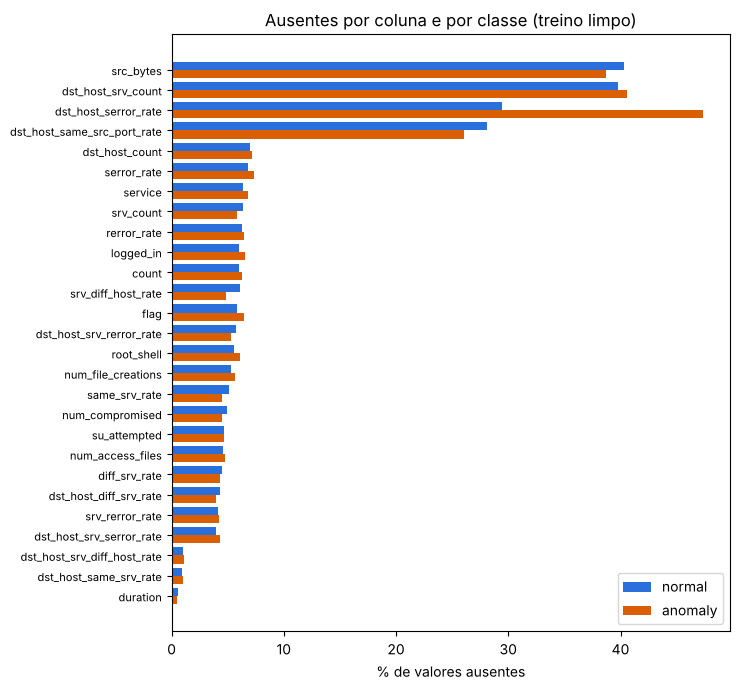

In [14]:
# gráfico 1: % de ausentes por coluna, separado por classe
d = aus.iloc[::-1]
pos = np.arange(len(d))
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(pos + 0.2, d["normal (%)"], height=0.4, color=AZUL, label="normal")
ax.barh(pos - 0.2, d["anomaly (%)"], height=0.4, color=LARANJA, label="anomaly")
ax.set_yticks(pos)
ax.set_yticklabels(d.index, fontsize=8)
ax.set_xlabel("% de valores ausentes")
ax.set_title("Ausentes por coluna e por classe (treino limpo)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusão do passo 1**

- 27 colunas têm ausentes: 25 numéricas e 2 de texto (`service` e `flag`). As que mais faltam são `src_bytes` (40,2%), `dst_host_srv_count` (39,8%), `dst_host_serror_rate` (30,0%) e `dst_host_same_src_port_rate` (28,1%). As outras ficam entre 0,5% e 7%.
- 94,2% das linhas do treino têm pelo menos um ausente. Se eu apagasse essas linhas, sobrariam 3.178 de 55.074, e no teste não dá para apagar nenhuma. Então a saída é imputar.
- As proporções são parecidas no treino e no teste. A exceção são `duration`, `dst_host_same_srv_rate` e `dst_host_srv_diff_host_rate`, que só têm ausentes no treino: esses ausentes vieram dos valores impossíveis que a Pessoa 1 transformou em `NaN`, e o teste não tinha nenhum.
- Em quase todas as colunas, a falta é igual nas duas classes (diferença de no máximo 2,1 pontos percentuais). A exceção é `dst_host_serror_rate`: falta em 29,4% das normais e em 47,4% das anomalias. Mesmo assim, o indicador "está ausente" dessa coluna, sozinho, separa pouco as classes (AUC de 0,59, em que 0,5 é não separar nada).

### 2. Imputação

Comparo seis formas de preencher os ausentes, todas com o `service` em one-hot:

- **mediana** (referência): não é puxada pelos valores extremos, e bytes e contagens são muito assimétricos;
- **média**: a alternativa simples, mas sofre com os extremos;
- **mediana + indicador de `dst_host_serror_rate`**: além de preencher, cria uma coluna 0/1 dizendo se o valor estava ausente, só na coluna em que a Etapa 1 viu a ausência ligada à classe;
- **mediana + indicadores em todas**: a mesma ideia, uma coluna 0/1 para cada atributo com ausente (`add_indicator=True`);
- **iterativa** (`IterativeImputer`): prevê cada coluna ausente a partir das outras, em rodadas. É a alternativa multivariada;
- **mediana + categoria "ausente" nos textos**: em vez de usar a moda, o `service` ou a `flag` ausente vira uma categoria própria.

Nos textos, a referência é a moda (o valor mais comum).

Também pensei no `KNNImputer`. Num teste com um fold, ele levou cerca de 40 segundos só para preencher as 11 mil linhas da validação; o treino de cada fold é 4 vezes maior, e isso se repetiria em 10 folds e 2 modelos. Deixei de fora pelo custo, e a iterativa já cobre a ideia de usar as outras colunas para preencher.

In [15]:
# codificação fixa (one-hot) para isolar o efeito da imputação
TEC_IMP = {
    "mediana (referência)":          dict(num="mediana", cat="moda", codificacao="onehot"),
    "média":                         dict(num="media", cat="moda", codificacao="onehot"),
    "mediana + indicador serror":    dict(num="mediana+indicador_serror", cat="moda", codificacao="onehot"),
    "mediana + indicadores (todas)": dict(num="mediana+indicadores", cat="moda", codificacao="onehot"),
    "iterativa (multivariada)":      dict(num="iterativa", cat="moda", codificacao="onehot"),
    "mediana + cat. 'ausente'":      dict(num="mediana", cat="constante", codificacao="onehot"),
}
res_imp, folds_imp = comparar(TEC_IMP, referencia="mediana (referência)")
display(res_imp.round(4))

,modelo,técnica,F1-macro,desvio,tempo (s),dif. p/ referência,folds em que ganhou
0,Regressão logística,mediana (referência),0.9302,0.0053,6.6147,0.0000,0/10
1,Regressão logística,média,0.9304,0.0059,5.6335,0.0001,4/10
2,Regressão logística,mediana + indicador serror,0.9296,0.0060,6.7146,-0.0007,3/10
3,Regressão logística,mediana + indicadores (todas),0.9300,0.0042,7.6346,-0.0002,5/10
4,Regressão logística,iterativa (multivariada),0.9322,0.0067,37.3074,0.0019,7/10
5,Regressão logística,mediana + cat. 'ausente',0.9332,0.0056,7.2262,0.0030,8/10
6,Random forest,mediana (referência),0.9728,0.0043,24.3344,0.0000,0/10
7,Random forest,média,0.9703,0.0050,22.5771,-0.0025,1/10
8,Random forest,mediana + indicador serror,0.9711,0.0048,23.7084,-0.0017,2/10
9,Random forest,mediana + indicadores (todas),0.9691,0.0059,24.7539,-0.0037,0/10


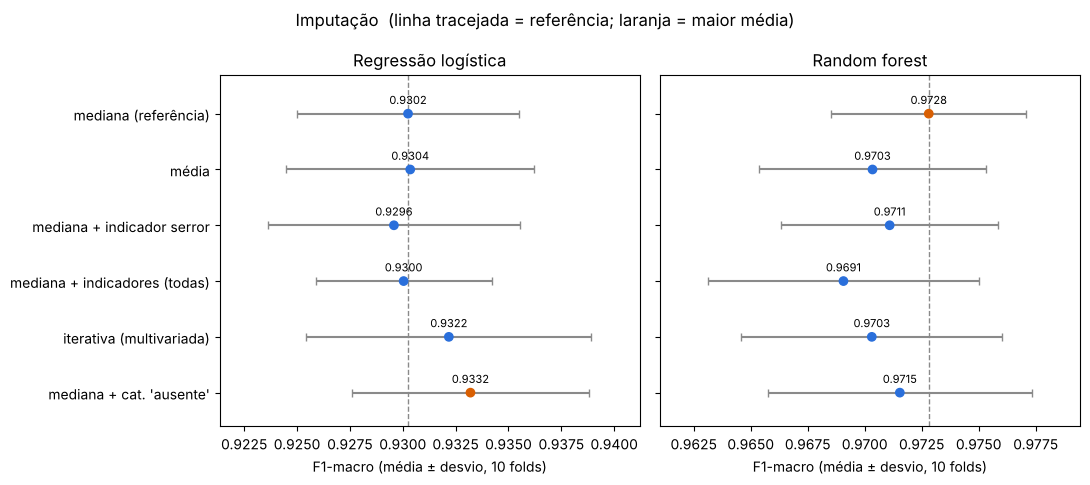

In [16]:
def grafico_comparacao(res, titulo):
    """Um painel por modelo: média do F1-macro nos 10 folds, com o desvio padrão."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * res["técnica"].nunique() + 1.6), sharey=True)
    ordem = list(dict.fromkeys(res["técnica"]))[::-1]
    for ax, (modelo, r) in zip(axes, res.groupby("modelo", sort=False)):
        r = r.set_index("técnica").loc[ordem]
        ref = r.iloc[-1]["F1-macro"]   # a referência é a primeira técnica da lista
        melhor = r["F1-macro"].idxmax()
        cores = [LARANJA if t == melhor else AZUL for t in r.index]
        ax.errorbar(r["F1-macro"], np.arange(len(r)), xerr=r["desvio"], fmt="none", ecolor=CINZA, capsize=3)
        ax.scatter(r["F1-macro"], np.arange(len(r)), color=cores, zorder=3)
        ax.axvline(ref, color=CINZA, ls="--", lw=1)
        for i, v in enumerate(r["F1-macro"]):
            ax.annotate(f"{v:.4f}", (v, i), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
        ax.set_ylim(-0.6, len(r) - 0.3)   # espaço para o número da primeira linha
        ax.set_yticks(np.arange(len(r)))
        ax.set_yticklabels(r.index)
        ax.set_title(modelo)
        ax.set_xlabel("F1-macro (média ± desvio, 10 folds)")
        lo = (r["F1-macro"] - r["desvio"]).min(); hi = (r["F1-macro"] + r["desvio"]).max()
        ax.set_xlim(lo - (hi - lo) * 0.15, hi + (hi - lo) * 0.15)
    fig.suptitle(titulo + "  (linha tracejada = referência; laranja = maior média)")
    plt.tight_layout(); plt.show()

grafico_comparacao(res_imp, "Imputação")

In [17]:
IMP_NOME = escolher(res_imp, referencia="mediana (referência)")

modelo,dif. Random forest,dif. Regressão logística,não piora nenhum,ganha em ≥8/10 em algum,passa
técnica,,,,,
mediana (referência),0.0000,0.0000,—,—,—
média,-0.0025,0.0001,False,False,False
mediana + indicador serror,-0.0017,-0.0007,False,False,False
mediana + indicadores (todas),-0.0037,-0.0002,False,False,False
iterativa (multivariada),-0.0025,0.0019,False,False,False
mediana + cat. 'ausente',-0.0013,0.0030,False,True,False


Escolhida: mediana (referência)


**Conclusão do passo 2**

- Na random forest, nenhuma alternativa bateu a mediana: todas tiveram média menor e perderam na maioria dos folds. A pior foi colocar indicadores em todas as colunas (−0,0037, ganhou em 0 de 10 folds).
- Na regressão logística, a categoria "ausente" nos textos foi a melhor (+0,0030, ganhou em 8 de 10 folds), e a iterativa também ajudou (+0,0019, ganhou em 7 de 10 folds). Mas as duas pioram a random forest, e a iterativa ainda demora cerca de 3 vezes mais que a mediana.
- Os indicadores de ausência não ajudaram em nenhum dos dois modelos, nem o de `dst_host_serror_rate` que a Etapa 1 sugeriu testar (−0,0007, ganhou em 3 de 10 folds na regressão logística, −0,0017, ganhou em 2 de 10 folds na random forest). A diferença entre as classes existe, mas é fraca, como o passo 1 mostrou. E os indicadores em todas as colunas criam três colunas que no teste são sempre 0 (`duration` e as duas taxas do passo 1), porque lá nunca falta valor nelas.
- **Escolha: mediana nos números e moda nos textos.** Nenhuma alternativa passou na regra, porque todas pioram a random forest. Ela também é simples e rápida.
- Se o grupo acabar usando um modelo linear, vale trocar a moda pela categoria "ausente" nos textos (`cat="constante"` no `montar_preprocessador`).

### 3. Codificação dos categóricos

`protocol_type` (3 valores) e `flag` (11 valores) têm poucas categorias, então ficam sempre em one-hot. O problema é o `service`. Antes de comparar, vejo quantas categorias ele tem, quantas são raras, se o teste traz alguma que o treino não tem e quantas colunas cada codificação gera.

In [18]:
cont = X["service"].value_counts()
raras = cont[cont < 50]
so_teste = sorted(set(X_teste["service"].dropna()) - set(cont.index))

print(f"service: {len(cont)} categorias no treino (protocol_type tem {X['protocol_type'].nunique()} e flag tem {X['flag'].nunique()})")
print(f"As 5 maiores cobrem {cont.head(5).sum() / cont.sum() * 100:.1f}% das linhas: {cont.head(5).index.tolist()}")
print(f"Categorias com menos de 50 linhas: {len(raras)} (somam {raras.sum()} linhas, {raras.sum() / cont.sum() * 100:.2f}%)")
print(f"Categorias com 1 linha só: {(cont == 1).sum()} -> {cont[cont == 1].index.tolist()}")
print(f"Serviços do teste que não existem no treino limpo: {so_teste} "
      f"({X_teste['service'].isin(so_teste).sum()} linhas do teste)")

# a codificação por frequência junta categorias que têm a mesma contagem
repetidas = cont.groupby(cont).size()
repetidas = repetidas[repetidas > 1]
print(f"Frequência: {repetidas.sum()} categorias dividem o mesmo valor com outra ({len(repetidas)} valores repetidos)")

# taxa de anomalia por serviço: mostra que categorias diferentes com a mesma frequência podem ter classe bem diferente
taxa = (y.groupby(X["service"]).mean() * 100).rename("% anomaly")
por_serv = pd.DataFrame({"linhas": cont, "% anomaly": taxa})
amplitude = por_serv[por_serv["linhas"].isin(repetidas.index)].groupby("linhas")["% anomaly"].agg(lambda t: t.max() - t.min())
n_ex = amplitude.idxmax()   # a contagem repetida em que os serviços são mais diferentes entre si
print(f"\nExemplo de colisão: serviços com exatamente {n_ex} linhas no treino (viram o mesmo número na frequência)")
display(por_serv[por_serv["linhas"] == n_ex].round(1))

# quantas colunas cada codificação gera no treino inteiro
n_cols = {}
for cod in ["onehot", "onehot_raras", "frequencia", "alvo", "ordinal"]:
    pre = montar_preprocessador(num="mediana", cat="moda", codificacao=cod)
    n_cols[cod] = pre.fit(X, y).transform(X.head(5)).shape[1]
display(pd.Series(n_cols, name="colunas na saída").to_frame())

service: 65 categorias no treino (protocol_type tem 3 e flag tem 11)
As 5 maiores cobrem 88.6% das linhas: ['http', 'domain_u', 'smtp', 'ftp_data', 'private']
Categorias com menos de 50 linhas: 48 (somam 605 linhas, 1.17%)
Categorias com 1 linha só: 2 -> ['pop_2', 'http_2784']
Serviços do teste que não existem no treino limpo: ['pm_dump', 'printer'] (2 linhas do teste)
Frequência: 40 categorias dividem o mesmo valor com outra (14 valores repetidos)

Exemplo de colisão: serviços com exatamente 3 linhas no treino (viram o mesmo número na frequência)


,linhas,% anomaly
service,,
remote_job,3,100.0
shell,3,33.3
tftp_u,3,0.0


,colunas na saída
onehot,116
onehot_raras,69
frequencia,52
alvo,52
ordinal,52


**O que o diagnóstico mostra sobre o `service`**

- São 65 categorias, mas as 5 maiores cobrem 88,6% das linhas. 48 categorias têm menos de 50 linhas (juntas, só 1,17% do treino) e 2 aparecem uma vez só. Com one-hot, cada uma vira uma coluna quase sempre zerada, e a base sai de 40 para 116 colunas.
- O teste tem 2 serviços que não existem no treino limpo: `pm_dump` e `printer` (1 linha cada). Eles existiam no treino original, mas todas as linhas deles estavam em grupos contraditórios (atributos iguais, classes diferentes) e saíram na limpeza. A codificação precisa aceitar categoria desconhecida sem dar erro.
- Na codificação por frequência, serviços com a mesma contagem viram o mesmo número: 40 serviços dividem o valor com algum outro. No exemplo acima, três serviços com 3 linhas cada vão de 0% a 100% de anomalias e mesmo assim ficariam iguais para o modelo.

Comparo cinco codificações para o `service`, todas com a imputação escolhida no passo 2:

- **one-hot** (referência): uma coluna por serviço (116 colunas no total);
- **one-hot com raras juntas** (`min_frequency=50`): serviços com menos de 50 linhas no treino do fold viram uma coluna só, e um serviço desconhecido no teste cai nessa mesma coluna (69 colunas);
- **frequência**: uma coluna com a proporção de linhas de cada serviço no treino; serviço desconhecido vira 0 (52 colunas);
- **alvo** (*target encoding*, `TargetEncoder`): uma coluna com a taxa de anomalia de cada serviço. Dentro do `fit` ele usa validação cruzada interna, para que nenhuma linha seja codificada com o próprio rótulo (52 colunas);
- **ordinal**: um número por serviço, em ordem alfabética. Entra como contraexemplo, porque inventa uma ordem que não existe (52 colunas).

In [19]:
# imputação fixa (a escolhida no passo 2) para isolar o efeito da codificação
IMP_ESCOLHIDA = {k: v for k, v in TEC_IMP[IMP_NOME].items() if k != "codificacao"}
TEC_COD = {
    "one-hot (referência)":       dict(**IMP_ESCOLHIDA, codificacao="onehot"),
    "one-hot com raras juntas":   dict(**IMP_ESCOLHIDA, codificacao="onehot_raras"),
    "frequência":                 dict(**IMP_ESCOLHIDA, codificacao="frequencia"),
    "alvo (target encoding)":     dict(**IMP_ESCOLHIDA, codificacao="alvo"),
    "ordinal":                    dict(**IMP_ESCOLHIDA, codificacao="ordinal"),
}
res_cod, folds_cod = comparar(TEC_COD, referencia="one-hot (referência)")
display(res_cod.round(4))

,modelo,técnica,F1-macro,desvio,tempo (s),dif. p/ referência,folds em que ganhou
0,Regressão logística,one-hot (referência),0.9302,0.0053,6.5620,0.0000,0/10
1,Regressão logística,one-hot com raras juntas,0.9308,0.0057,5.2260,0.0006,5/10
2,Regressão logística,frequência,0.9183,0.0049,4.3836,-0.0119,0/10
3,Regressão logística,alvo (target encoding),0.9321,0.0059,4.2553,0.0019,7/10
4,Regressão logística,ordinal,0.9108,0.0037,4.3192,-0.0195,0/10
5,Random forest,one-hot (referência),0.9728,0.0043,22.4037,0.0000,0/10
6,Random forest,one-hot com raras juntas,0.9750,0.0041,23.2298,0.0022,10/10
7,Random forest,frequência,0.9745,0.0045,22.9492,0.0017,6/10
8,Random forest,alvo (target encoding),0.9748,0.0041,22.6937,0.0020,6/10
9,Random forest,ordinal,0.9735,0.0054,21.0913,0.0007,6/10


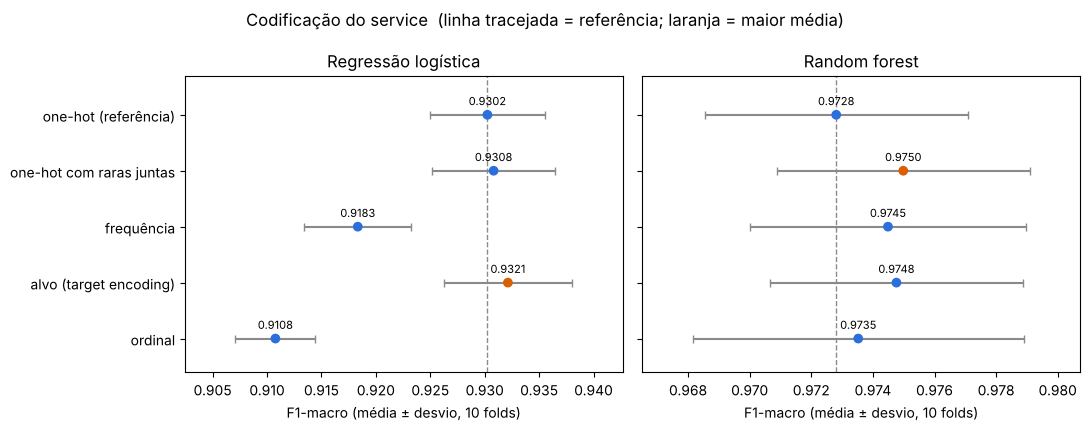

In [20]:
grafico_comparacao(res_cod, "Codificação do service")

In [21]:
COD_NOME = escolher(res_cod, referencia="one-hot (referência)")
ESCOLHA = TEC_COD[COD_NOME]

modelo,dif. Random forest,dif. Regressão logística,não piora nenhum,ganha em ≥8/10 em algum,passa
técnica,,,,,
one-hot (referência),0.0000,0.0000,—,—,—
one-hot com raras juntas,0.0022,0.0006,True,True,True
frequência,0.0017,-0.0119,False,False,False
alvo (target encoding),0.0020,0.0019,True,False,False
ordinal,0.0007,-0.0195,False,False,False


Escolhida: one-hot com raras juntas


**Conclusão do passo 3**

- **One-hot com raras juntas** ganhou da referência na random forest em todos os 10 folds (+0,0022, ganhou em 10 de 10 folds) e empatou na regressão logística (+0,0006, ganhou em 5 de 10 folds). Juntar os serviços raros tira 47 colunas quase sempre zeradas, que apareciam em tão poucas linhas que davam pouco para o modelo aprender.
- A codificação pelo **alvo** chegou perto: melhorou os dois modelos (+0,0019, ganhou em 7 de 10 folds na regressão logística e +0,0020, ganhou em 6 de 10 folds na random forest) e teve a maior média na regressão logística. Mas não ganhou em 8 dos 10 folds em nenhum dos dois, então pela regra não dá para separar essa melhora de sorte na divisão dos folds. Ela também é a única que usa o rótulo para codificar, o que pede mais cuidado.
- **Frequência** ajudou um pouco a random forest (+0,0017, ganhou em 6 de 10 folds), mas derrubou a regressão logística (−0,0119, ganhou em 0 de 10 folds), que perdeu nos 10 folds. É o efeito das colisões: serviços diferentes viram o mesmo número, e um modelo linear ainda lê esse número como "mais é maior".
- **Ordinal** foi a pior na regressão logística (−0,0195, ganhou em 0 de 10 folds), como esperado: a ordem alfabética não quer dizer nada. Na random forest quase não mudou (+0,0007, ganhou em 6 de 10 folds), porque as árvores conseguem separar os números em vários cortes.
- **Escolha: one-hot com raras juntas.** Foi a única que passou na regra. Ela não depende do rótulo (sem risco de vazamento), trata os serviços novos do teste e entrega 69 colunas em vez de 116, o que também deixa mais leve o PCA da Pessoa 3 e o SMOTE da Pessoa 4.

### 4. Conferindo a escolha no teste

Ajusto o pré-processamento escolhido no treino inteiro e aplico no teste, que é o que a Pessoa 4 vai fazer no final. Confiro que não sobra nenhum `NaN`, que o teste continua com todas as linhas, que treino e teste saem com as mesmas colunas e que os dois serviços novos do teste não quebram nada.

In [22]:
# a configuração escolhida, do jeito que a Pessoa 4 vai usar
pre_final = montar_preprocessador(**ESCOLHA)
pre_final.fit(X, y)
Xt_treino = pre_final.transform(X)
Xt_teste = pre_final.transform(X_teste)
nomes = pre_final.get_feature_names_out()

conferencias = {
    "nenhum NaN depois do pré-processamento (treino)": not np.isnan(Xt_treino).any(),
    "nenhum NaN depois do pré-processamento (teste)": not np.isnan(Xt_teste).any(),
    "teste continua com 24.333 linhas": Xt_teste.shape[0] == 24333,
    "treino e teste com as mesmas colunas": Xt_treino.shape[1] == Xt_teste.shape[1],
    "serviços novos do teste caem na coluna dos raros": bool(
        (Xt_teste[X_teste["service"].isin(so_teste).to_numpy(), list(nomes).index("service_infrequent_sklearn")] == 1).all()),
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values())
print(f"\nEscolha: {ESCOLHA}")
print(f"Colunas na saída: {Xt_treino.shape[1]} (eram {X.shape[1]} atributos)")
print("Algumas colunas:", list(nomes[:3]), "...", list(nomes[-4:]))

OK   nenhum NaN depois do pré-processamento (treino)
OK   nenhum NaN depois do pré-processamento (teste)
OK   teste continua com 24.333 linhas
OK   treino e teste com as mesmas colunas
OK   serviços novos do teste caem na coluna dos raros

Escolha: {'num': 'mediana', 'cat': 'moda', 'codificacao': 'onehot_raras'}
Colunas na saída: 69 (eram 40 atributos)
Algumas colunas: ['duration', 'src_bytes', 'dst_bytes'] ... ['service_telnet', 'service_time', 'service_urp_i', 'service_infrequent_sklearn']


**Conclusão do passo 4**

- O pré-processamento roda no teste sem erro e sem deixar `NaN`. As 24.333 linhas continuam lá, com as mesmas 69 colunas do treino.
- `pm_dump` e `printer`, que não existem no treino, caem na coluna dos serviços raros (`service_infrequent_sklearn`), em vez de virarem uma linha toda zerada ou darem erro.

### 5. Resumo

Todas as técnicas testadas, com a média do F1-macro nos 10 folds. Os números saem das variáveis do notebook, não foram digitados.

In [23]:
fmt4 = lambda v: f"{v:.4f}"
def linha(res, tec):
    r = res[res["técnica"] == tec].set_index("modelo")
    return [fmt4(r.loc["Regressão logística", "F1-macro"]), fmt4(r.loc["Random forest", "F1-macro"])]

tab = pd.DataFrame(
    [["Imputação", t] + linha(res_imp, t) for t in TEC_IMP] +
    [["Codificação do service", t] + linha(res_cod, t) for t in TEC_COD],
    columns=["etapa", "técnica", "F1-macro (reg. logística)", "F1-macro (random forest)"])
tab["escolhida"] = ["sim" if t in (IMP_NOME, COD_NOME) else "" for t in tab["técnica"]]
display(tab.style.hide(axis="index"))

etapa,técnica,F1-macro (reg. logística),F1-macro (random forest),escolhida
Imputação,mediana (referência),0.9302,0.9728,sim
Imputação,média,0.9304,0.9703,
Imputação,mediana + indicador serror,0.9296,0.9711,
Imputação,mediana + indicadores (todas),0.9300,0.9691,
Imputação,iterativa (multivariada),0.9322,0.9703,
Imputação,mediana + cat. 'ausente',0.9332,0.9715,
Codificação do service,one-hot (referência),0.9302,0.9728,
Codificação do service,one-hot com raras juntas,0.9308,0.9750,sim
Codificação do service,frequência,0.9183,0.9745,
Codificação do service,alvo (target encoding),0.9321,0.9748,


**Para quem for usar (Pessoa 4):**

```python
from ausentes_codificacao import montar_preprocessador

pre = montar_preprocessador(num="mediana", cat="moda", codificacao="onehot_raras")
pipe = Pipeline([("pre", pre), ("modelo", ...)])   # o pré-processamento vem antes de tudo
```

- O `montar_preprocessador()` já inclui um `StandardScaler` nos números. Se a Pessoa 3 escolher outro tratamento (`log1p`, `RobustScaler`), é só trocar essa parte no arquivo.
- Ele tem que ser o **primeiro passo** do pipeline, antes do SMOTE: o SMOTE trabalha com distâncias, então precisa receber tudo já sem `NaN` e em números.
- `X` não pode ter `class` nem `id`. Com `score_ids_legado`, ela entra automaticamente como mais uma coluna numérica.
- Quando o `avaliar()` oficial da Pessoa 1 sair, vale rodar esta seção de novo com ele. Se as escolhas mudarem, a função `escolher()` mostra isso na hora; só o texto das conclusões teria que ser atualizado.

## Pessoa 3 — Transformação e redução

**Entrega:** comparação das técnicas e a justificativa.

- Transformação numérica: `log1p` nos bytes e na duração; StandardScaler × RobustScaler
- Redução de dimensionalidade com PCA (ou seleção de instâncias)

In [13]:
# Pessoa 3


## Pessoa 4 — Balanceamento e integração

**Entrega:** comparação do balanceamento, notebook integrado e tabela final.

- SMOTE × RandomUnderSampler (Pipeline do imblearn), mais `class_weight="balanced"` como referência
- Juntar as partes no notebook final
- Montar a tabela comparativa geral

In [14]:
# Pessoa 4
